# Exercise 1: From municipalities to counties

Each Norwegian municipality (*kommune*) belongs to a county (*fylke*). In this
exercise, you will use municipality-level data from Statistics Norway (SSB) to
compare counties by their number of municipalities, population, and population
density.

1.  Load `municipalities.csv` from the `data/ssb/` folder. Keep only the columns
    `municipality`, `county`, `population`, and `land_area`, and display the first
    five rows.

    Each row represents one municipality. The column `population` records its
    number of residents, and `land_area` records its land area in km².

2.  Group the data by `county` and count the municipalities in each county.
    Display the counts in descending order. Which county contains the most
    municipalities?

    *Hint:* Applying `size()` to a grouped DataFrame counts the rows in each group.
    Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the counts.

3.  Create a DataFrame named `df_counties` containing the total population and
    total land area of each county. Report the three counties with the largest
    populations.

    Check that summing the county populations gives the same national total as
    summing the municipality populations.

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

In [1]:
import pandas as pd

In [2]:

#Use DataPath to unlock local file system
DATAPATH = '../../data'
cols = ['municipality', 'county', 'population', 'land_area']

file = f'{DATAPATH}/ssb/municipalities.csv'

#Now we can select our wanted files and have a fresh data frame
df_municipalities = pd.read_csv(file) 

df_municipalities = df_municipalities[cols]

df_municipalities.head(5)



,municipality,county,population,land_area
0,Oslo,Oslo,724290,426
1,Bergen,Vestland,293709,445
2,Trondheim - Tråante,Trøndelag - Trööndelage,216518,496
3,Stavanger,Rogaland,150123,256
4,Bærum,Akershus,132358,189


In [3]:
# Count the number of municipalities in each county using groupby
municipality_count = df_municipalities.groupby('county').size()
municipality_count.sort_values(ascending= False).head(5)



county
Innlandet                  46
Vestland                   43
Nordland - Nordlánnda      41
Trøndelag - Trööndelage    38
Møre og Romsdal            27
dtype: int64

In [4]:
# 3.  Create a DataFrame named `df_counties` containing the total population and total land area of each county. 
# Report the three counties with the largest populations.Check that summing the county populations gives the same national total as summing the municipality populations.

df_county = df_municipalities.groupby('county')[['population', 'land_area']].sum()
df_county.sort_values(by=['population'], ascending= False).head(4)

,population,land_area
county,,
Akershus,740680,5471
Oslo,724290,426
Vestland,655210,31964
Rogaland,504496,8572


In [5]:
county_population = df_county['population'].sum()
municipality_population = df_municipalities['population'].sum()

county_population == municipality_population


np.True_

4.  Add a column named `density` to `df_counties`, containing each county's
    population density in residents per km² of land:

    $$
    \text{Population density} =
    \frac{\text{Total population}}{\text{Total land area}}
    $$

    Report the three counties with the highest population densities. Does the
    county with the largest population also have the highest population density?

***
# Exercise 2: House price levels and dispersion

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    To familiarize yourself with the data, report the columns present in the DataFrame and 
    then restrict the data to the columns `SalePrice` (price in thousands of US dollars) 
    and `Neighborhood` (abbreviated name of the neighborhood).
    
    Count the number of observations in each neighborhood. Drop all observations
    belonging to neighborhoods with fewer than 20 observations. Use this
    restricted data set for the remainder of the exercise.

    Check that there are no observations with missing values in the final data set.

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).

3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

In [6]:

file = f'{DATAPATH}/ames_houses.csv'
df_neighborhood = pd.read_csv(file)
df_neighborhood

,LotArea,Neighborhood,OverallQuality,OverallCondition,YearBuilt,YearRemodeled,BuildingType,CentralAir,LivingArea,Bathrooms,Bedrooms,Fireplaces,SalePrice,YearSold,MonthSold,HasGarage
0,2951.2,NAmes,6,5,1960,1960,Single-family,Y,153.8,1,3,2,215.0,2010,5,1
1,1079.6,NAmes,5,6,1961,1961,Single-family,Y,83.2,1,2,0,105.0,2010,6,1
2,1325.3,NAmes,6,6,1958,1958,Single-family,Y,123.5,1,3,0,172.0,2010,6,1
3,1036.7,NAmes,7,5,1968,1968,Single-family,Y,196.0,2,3,2,244.0,2010,4,1
4,1284.7,Gilbert,5,5,1997,1998,Single-family,Y,151.3,2,3,1,189.9,2010,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,737.3,Mitchel,6,6,1984,1984,Single-family,Y,93.2,1,3,0,142.5,2006,3,1
2926,825.4,Mitchel,5,5,1983,1983,Single-family,Y,83.8,1,2,0,131.0,2006,6,1
2927,969.9,Mitchel,5,5,1992,1992,Single-family,Y,90.1,1,3,0,132.0,2006,7,0
2928,929.9,Mitchel,5,5,1974,1975,Single-family,Y,129.0,1,2,1,170.0,2006,4,1


In [7]:
df_neighborhood.columns

Index(['LotArea', 'Neighborhood', 'OverallQuality', 'OverallCondition',
       'YearBuilt', 'YearRemodeled', 'BuildingType', 'CentralAir',
       'LivingArea', 'Bathrooms', 'Bedrooms', 'Fireplaces', 'SalePrice',
       'YearSold', 'MonthSold', 'HasGarage'],
      dtype='str')

In [8]:
df_neighborhood = df_neighborhood[['SalePrice', 'Neighborhood']]
df_neighborhood

,SalePrice,Neighborhood
0,215.0,NAmes
1,105.0,NAmes
2,172.0,NAmes
3,244.0,NAmes
4,189.9,Gilbert
...,...,...
2925,142.5,Mitchel
2926,131.0,Mitchel
2927,132.0,Mitchel
2928,170.0,Mitchel


In [9]:
Neighborhood_counts = df_neighborhood['Neighborhood'].value_counts()
Neighborhood_counts

Valid_Neighborhood = Neighborhood_counts[
    Neighborhood_counts >= 20
    ].index

Valid_Neighborhood

Index(['NAmes', 'CollgCr', 'OldTown', 'Edwards', 'Somerst', 'NridgHt',
       'Gilbert', 'Sawyer', 'NWAmes', 'SawyerW', 'Mitchel', 'BrkSide',
       'Crawfor', 'IDOTRR', 'Timber', 'NoRidge', 'StoneBr', 'SWISU', 'ClearCr',
       'MeadowV', 'BrDale', 'Blmngtn', 'Veenker', 'NPkVill'],
      dtype='str', name='Neighborhood')

In [10]:
df_neighborhood_restriced = df_neighborhood[df_neighborhood['Neighborhood'].isin(Valid_Neighborhood)].copy()
df_neighborhood_restriced = (df_neighborhood_restriced.reset_index(drop= True))
df_neighborhood_restriced

,SalePrice,Neighborhood
0,215.0,NAmes
1,105.0,NAmes
2,172.0,NAmes
3,244.0,NAmes
4,189.9,Gilbert
...,...,...
2904,142.5,Mitchel
2905,131.0,Mitchel
2906,132.0,Mitchel
2907,170.0,Mitchel


In [11]:
#Check for any missing obervations
df_neighborhood_restriced['SalePrice'].isna().sum()


np.int64(0)

2.  Compute the average house price (column `SalePrice`) by neighborhood (column
    `Neighborhood`). List the three neighborhoods with the highest average prices,
    for example by using
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html).

    Create a bar chart showing the average sale price for all remaining
    neighborhoods in descending order.

    *Hint:* You can create the bar chart by either using pandas's 
    [`DataFrame.plot.bar()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.bar.html)
    or Matplotlib's
    [`bar()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).


In [12]:
df = df_neighborhood_restriced 

average_price = (df.groupby('Neighborhood')['SalePrice'].mean())

cleaned_average_price = average_price.sort_values(ascending= False).round().astype(int)
cleaned_average_price

Neighborhood
NoRidge    330
StoneBr    324
NridgHt    322
Veenker    248
Timber     247
Somerst    230
ClearCr    209
Crawfor    208
CollgCr    202
Blmngtn    197
Gilbert    191
NWAmes     188
SawyerW    184
Mitchel    162
NAmes      145
NPkVill    141
Sawyer     137
SWISU      135
Edwards    131
BrkSide    125
OldTown    124
BrDale     106
IDOTRR     104
MeadowV     96
Name: SalePrice, dtype: int64

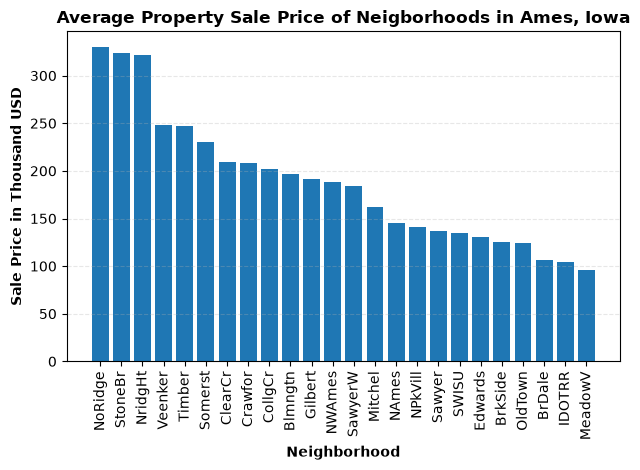

In [13]:
import matplotlib.pyplot as plt

x_values = cleaned_average_price.index
y_values = cleaned_average_price.values

plt.bar(x_values, y_values)
plt.xticks(rotation=90)
plt.xlabel('Neighborhood', weight='bold')
plt.ylabel('Sale Price in Thousand USD', weight='bold')
plt.title('Average Property Sale Price of Neigborhoods in Ames, Iowa', weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()


3.  You want to quantify the price dispersion in each neighborhood. To this end, compute the standard deviation of the sale price by neighborhood using 
    [`std()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html).
    Which are the three neighborhoods with the most dispersed prices?

In [14]:
#Let us return to df_neighborhood_restricted
std_neighborhood = (df.groupby('Neighborhood')['SalePrice'].std())
std_neighborhood = std_neighborhood.round().astype(int).sort_values(ascending= False)
std_neighborhood

Neighborhood
StoneBr    119
NoRidge    101
NridgHt     96
Timber      69
Crawfor     65
Veenker     65
Somerst     57
CollgCr     54
ClearCr     51
SawyerW     49
Edwards     48
OldTown     44
Mitchel     41
NWAmes      38
IDOTRR      36
BrkSide     36
Gilbert     33
NAmes       32
SWISU       31
Blmngtn     29
Sawyer      23
MeadowV     20
BrDale      12
NPkVill      9
Name: SalePrice, dtype: int64

4.  Create a scatter plot with the average house price on the $x$-axis and the standard deviation on the $y$-axis.
    Is there a relationship between the average house prices and their dispersion within a neighborhood?

    *Hint:* You can create the scatter plot by either using pandas's 
    [`DataFrame.plot.scatter()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.scatter.html)
    or Matplotlib's 
    [`scatter()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html).


In [15]:
#Before making the plot we need to make a data frame where each standard deviation value is equal to its corresponding average value for each neighborhood
summary = df.groupby('Neighborhood')['SalePrice'].agg(
    average= 'mean',
    standard_deviation= 'std'
)
summary

,average,standard_deviation
Neighborhood,,
Blmngtn,196.660714,29.325344
BrDale,105.610000,12.145649
BrkSide,124.756481,35.741170
ClearCr,208.661364,51.281291
CollgCr,201.804120,54.188895
Crawfor,207.552427,65.229074
Edwards,130.843814,48.030072
Gilbert,190.646667,33.049884
IDOTRR,103.751613,36.494325


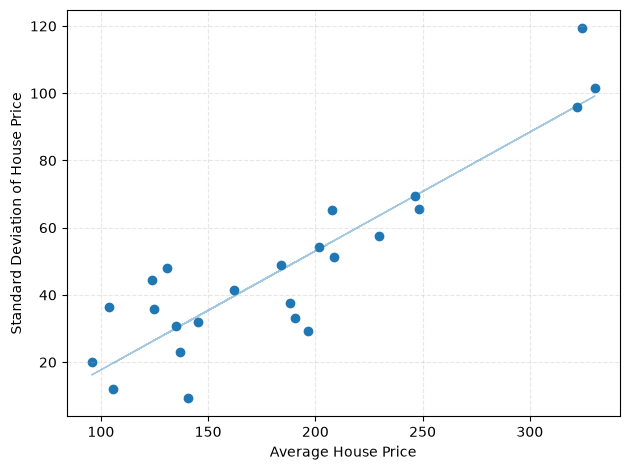

In [16]:
import matplotlib.pyplot as plt
import numpy as np 


x = summary['average']
y = summary['standard_deviation']

# Fit linear regression
slope, intercept = np.polyfit(x,y, deg=1)
# Create the Slopeline
regression_line = slope * x + intercept

# Plot using matplotlib
plt.scatter(x, y)
plt.plot(x, regression_line, linestyle='-', linewidth=1, alpha=0.4)

plt.xlabel('Average House Price')
plt.ylabel('Standard Deviation of House Price')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()

5.  **[Advanced]** To compare neighborhoods with different average prices,
    express the standard deviation as a percentage of the average price:

    $$
    \text{Relative price spread (\%)} =
    100 \times \frac{\text{standard deviation}}{\text{average price}}
    $$

    This is the
    [coefficient of variation](
    https://www.itl.nist.gov/div898/software/dataplot/refman2/auxillar/coefvari.htm
    )
    expressed as a percentage. For example, a standard deviation of 20 thousand
    USD and an average price of 100 thousand USD give a relative spread of 20%.

    Calculate the relative price spread for each neighborhood. Create a scatter
    plot with the average house price on the $x$-axis and the relative price spread
    on the $y$-axis. Do neighborhoods with higher average prices also have more
    dispersed prices relative to their average? Compare the pattern with Part 4.

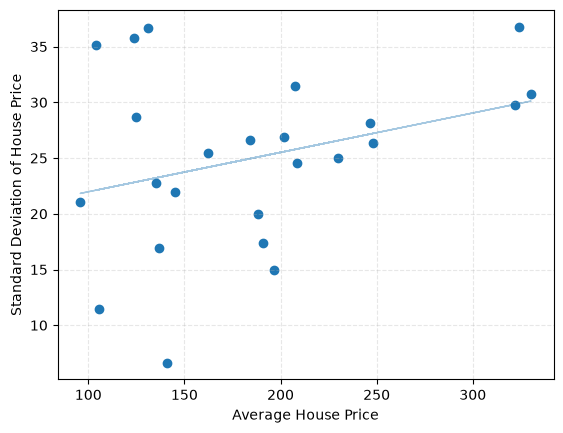

In [17]:
# We need to make a new column in summary with the Relative Price spead for each neighborhood
summary['relative_price_spread'] = (100 * summary['standard_deviation'] / summary['average'])
summary = summary.sort_values(by=['relative_price_spread'], ascending=False)


x = summary['average']
y = summary['relative_price_spread']

# Fit linear regression
slope, intercept = np.polyfit(x,y, deg=1)
# Create the Slopeline
regression_line = slope * x + intercept

# Plot using matplotlib
plt.scatter(x, y)
plt.plot(x, regression_line, linestyle='-', linewidth=1, alpha=0.4)

plt.xlabel('Average House Price')
plt.ylabel('Standard Deviation of House Price')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.grid(axis='x', linestyle='--', alpha=0.3)

***
# Exercise 3: Determinants of house prices

For this exercise, we're using around 3,000 observations of house prices and house
characteristics from Ames, a small city in Iowa, to understand how house prices vary
with selected house characteristics.

1.  Load the Ames housing data set from `ames_houses.csv` located in the `data/` folder.

    Keep only the columns `SalePrice` (price in thousands of US dollars), `LotArea` (lot area in m²), `YearBuilt`, and `Bedrooms` (number of bedrooms).

    Restrict your data set to houses with one or more bedrooms and a lot area of at least 100 m².
    Report the sample size after applying these restrictions.

2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

4.  Compute the mean sale price and number of observations within each group
    formed by `Newer` and `Rooms` (for a total of 6 different categories).

    By how much does the average price of newer houses with 4+ bedrooms exceed that
    of older houses with 1–2 bedrooms?

5.  Create a figure with two subplots arranged in two columns. The left column
    should contain a bar chart showing the average house price by the number of
    bedrooms (1–2, 3, 4+) for _older_ houses, whereas the right column should show the
    corresponding bars for _newer_ houses. Use a shared vertical scale so that prices
    can be compared across the two panels.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 

file = f'{DATAPATH}/ames_houses.csv'
full_houses = pd.read_csv(file)
df = full_houses[['SalePrice', 'LotArea', 'YearBuilt', 'Bedrooms']].copy()

filtered_df = df[
    (df['Bedrooms']>= 1)
    &(df['LotArea']>= 100)].copy()
filtered_df = filtered_df.reset_index(drop= True)
filtered_df



2.  Compute the average year in which a house was built (using the column `YearBuilt`). 

    Classify houses as _"newer"_ if they were built after the sample's average
    construction year, and _"older"_ otherwise. Store this classification in a new
    column `Newer`, with 1 for newer houses and 0 for older houses.

    What is the average year of construction within these two categories?

In [ ]:
Average_YearBuilt = filtered_df['YearBuilt'].mean()
Average_YearBuilt = Average_YearBuilt.astype(int)
filtered_df['Newer'] = (filtered_df['YearBuilt'] > Average_YearBuilt).astype(int)
filtered_df

In [ ]:
#Calculate the average Building Age between both categories
Age_Grouped = filtered_df.groupby('Newer')['YearBuilt'].mean()
Age_Grouped

3.  Create a new column `Rooms` which categorizes the number of `Bedrooms` into
    three groups: 1–2, 3, and 4 or more. Use the values 2, 3, and 4 to represent
    these groups. You can create these categories using boolean indexing,
    [`np.where()`](https://numpy.org/doc/2.0/reference/generated/numpy.where.html),
    pandas's
    [`where()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.where.html),
    [`map()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.map.html),
    [`clip()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.clip.html),
    or some other way.

In [ ]:
filtered_df['Bedrooms'].max()
#Hence this excercise is not relevant because cateogrising bedrooms with 8 should not be made into 4

***
# Exercise 4: Inflation and unemployment in the US

In this exercise, you'll be working with monthly observations of selected
macroeconomic variables for the United States obtained from
[FRED](https://fred.stlouisfed.org/).
The data set starts in 1948 and contains observations for a total of 936 months.

1.  Load the data from the file `FRED_monthly.csv` located in the `data/FRED`
    folder. Parse `DATE` as dates and use it as the DataFrame index. Sort the
    observations in chronological order, then print the first 10 observations to
    get an idea of what the data looks like.

    Keep only the columns `Year`, `Month`, `CPI`, and `UNRATE`, retaining the date
    index. Perform this analysis only on observations prior to 1970 and drop the
    rest, leaving the sample period 1948–1969.

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.

    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

In [32]:
file = f'{DATAPATH}/FRED/FRED_monthly.csv'
df = pd.read_csv(file, parse_dates=['DATE'])
df = df.set_index('DATE')
#df.index to double check that the dates are date time objects 
df = df.sort_index()
df.info

<bound method DataFrame.info of             Year  Month    CPI  UNRATE  FEDFUNDS  REALRATE  LFPART
DATE                                                              
1948-01-01  1948      1   23.7     3.4       NaN       NaN    58.6
1948-02-01  1948      2   23.7     3.8       NaN       NaN    58.9
1948-03-01  1948      3   23.5     4.0       NaN       NaN    58.5
1948-04-01  1948      4   23.8     3.9       NaN       NaN    59.0
1948-05-01  1948      5   24.0     3.5       NaN       NaN    58.3
...          ...    ...    ...     ...       ...       ...     ...
2025-08-01  2025      8  323.3     4.3       4.3       1.5    62.3
2025-09-01  2025      9  324.2     4.4       4.2       1.1    62.5
2025-10-01  2025     10    NaN     NaN       4.1       1.0     NaN
2025-11-01  2025     11  325.1     4.5       3.9       1.0    62.5
2025-12-01  2025     12  326.0     4.4       3.7      -0.1    62.4

[936 rows x 7 columns]>

In [34]:
df = df[['Year', 'Month', 'CPI', 'UNRATE']].copy()
df = df.query('Year < 1970')

2.  The column `CPI` stores the consumer price index (CPI) for the US.
    Create a new column `Inflation` which contains _year-over-year inflation in
    percent_: the percent change in the CPI relative to the same month in the
    previous year. Apply
    [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
    to the column `CPI`.


    *Hints:*

    -   Since this is monthly data, pass `periods=12` to `pct_change()` to get
        year-over-year changes.
    -   Multiply the values returned by `pct_change()` by 100 to get percent
        values.

In [40]:
df['Inflation'] = df['CPI'].pct_change(periods=12) * 100
df.head(24)

,Year,Month,CPI,UNRATE,Inflation
DATE,,,,,
1948-01-01,1948,1,23.7,3.4,NaN
1948-02-01,1948,2,23.7,3.8,NaN
1948-03-01,1948,3,23.5,4.0,NaN
1948-04-01,1948,4,23.8,3.9,NaN
1948-05-01,1948,5,24.0,3.5,NaN
1948-06-01,1948,6,24.2,3.6,NaN
1948-07-01,1948,7,24.4,3.6,NaN
1948-08-01,1948,8,24.4,3.9,NaN
1948-09-01,1948,9,24.4,3.8,NaN


3.  Compute the average unemployment rate (column `UNRATE`) over the restricted
    1948–1969 sample. Create a new column `UNRATE_HIGH` that contains an indicator
    whenever the unemployment rate is above its average value
    (_"high unemployment period"_).

    -   How many observations fall into the high- and low-unemployment periods?
    -   What is the average unemployment rate in the high- and low-unemployment periods?

In [51]:
AVG_UNRATE = df['UNRATE'].mean()
df['UNRATE_HIGH'] = (df['UNRATE'] > AVG_UNRATE).astype(int)
df['UNRATE_HIGH'].value_counts().sort_index()


UNRATE_HIGH
0    141
1    123
Name: count, dtype: int64

In [58]:
UNRATE_GROUPS = df.groupby(['UNRATE_HIGH'])
UNRATE_GROUPS['UNRATE'].mean(numeric_only= True)

UNRATE_HIGH
0    3.697872
1    5.781301
Name: UNRATE, dtype: float64

4.  Compute the average year-over-year inflation rate for high- and
    low-unemployment periods using the available observations. Is there any
    difference?

    Visualize this relationship by creating a scatter plot with the unemployment rate on the $x$-axis and inflation on the $y$-axis, and assign different colors 
    to observations from the low- and high-unemployment periods.

In [61]:
AVG_INFLATION_GROUPS = UNRATE_GROUPS['Inflation'].mean()
AVG_INFLATION_GROUPS

UNRATE_HIGH
0    3.110456
1    0.942056
Name: Inflation, dtype: float64

In [63]:
df.head(20)

,Year,Month,CPI,UNRATE,Inflation,UNRATE_HIGH
DATE,,,,,,
1948-01-01,1948,1,23.7,3.4,NaN,0
1948-02-01,1948,2,23.7,3.8,NaN,0
1948-03-01,1948,3,23.5,4.0,NaN,0
1948-04-01,1948,4,23.8,3.9,NaN,0
1948-05-01,1948,5,24.0,3.5,NaN,0
1948-06-01,1948,6,24.2,3.6,NaN,0
1948-07-01,1948,7,24.4,3.6,NaN,0
1948-08-01,1948,8,24.4,3.9,NaN,0
1948-09-01,1948,9,24.4,3.8,NaN,0


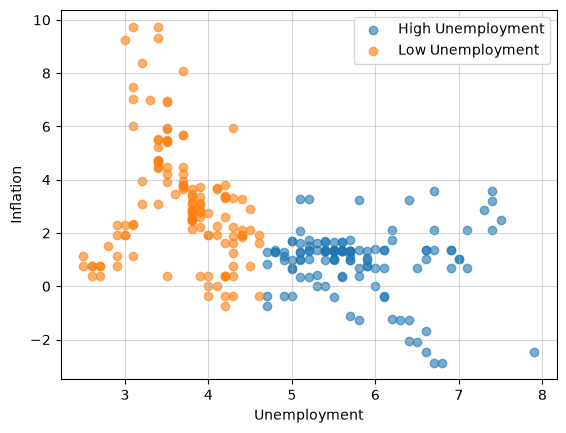

In [67]:
import matplotlib.pyplot as plt

high_unemployment = df[df['UNRATE_HIGH'] == 1]
low_unemployment = df[df['UNRATE_HIGH'] == 0]

plt.scatter(
    high_unemployment['UNRATE'], 
    high_unemployment['Inflation'], 
    label='High Unemployment',
    alpha=0.6,
    )

plt.scatter(
    low_unemployment['UNRATE'], 
    low_unemployment['Inflation'], 
    label='Low Unemployment',
    alpha=0.6,
    )

plt.xlabel('Unemployment')
plt.ylabel('Inflation')
plt.grid(axis='y', alpha=0.5)
plt.grid(axis='x', alpha=0.5)
plt.legend()

plt.show()

5.  Use 
    [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
    to compute the calendar-year average of the monthly year-over-year inflation
    rates.

    -   Report the three years with the highest averages.
    -   Create a plot that shows these calendar-year averages over the sample period.

    *Hint:* Use the resampling rule `'YE'` when calling `resample()`.

In [82]:
annual_inflation = (
    df['Inflation']
    .resample('YE')
    .mean()
)

#annual_inflation
print(f'The three years with the highest calendar-year average of monthly year-over-year inflation rates are {annual_inflation.sort_values(ascending= False).head(3).index[:3].tolist()}')


The three years with the highest calendar-year average of monthly year-over-year inflation rates are [Timestamp('1951-12-31 00:00:00'), Timestamp('1969-12-31 00:00:00'), Timestamp('1968-12-31 00:00:00')]


In [88]:
annual_inflation

DATE
1948-12-31         NaN
1949-12-31   -0.985248
1950-12-31    1.061340
1951-12-31    7.987456
1952-12-31    2.284891
1953-12-31    0.753193
1954-12-31    0.345766
1955-12-31   -0.216275
1956-12-31    1.461221
1957-12-31    3.403206
1958-12-31    2.702165
1959-12-31    0.981409
1960-12-31    1.486706
1961-12-31    0.986811
1962-12-31    1.226788
1963-12-31    1.294652
1964-12-31    1.252221
1965-12-31    1.637897
1966-12-31    2.984388
1967-12-31    2.770927
1968-12-31    4.241319
1969-12-31    5.432647
Freq: YE-DEC, Name: Inflation, dtype: float64

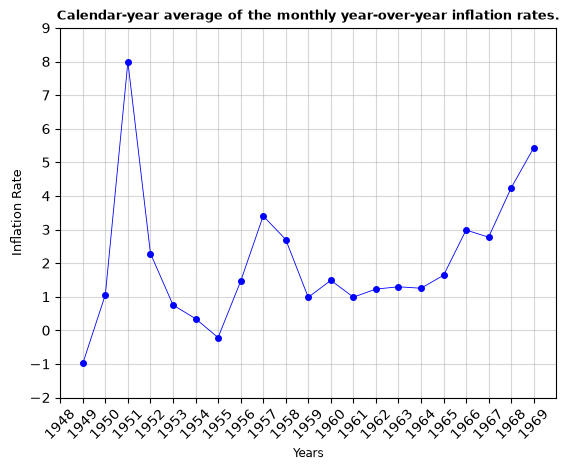

In [144]:
plt.plot(
    annual_inflation.index, 
    annual_inflation, 
    color='blue', 
    linestyle='solid', 
    linewidth=0.6, 
    marker='o', 
    markersize=4
    )

plt.grid(alpha=0.5)
plt.xticks(
    ticks=annual_inflation.index,
    labels=annual_inflation.index.year,
    rotation=45,
    ha='center',
)
plt.yticks(range(-2, 10))
plt.xlabel('Years', fontsize=8.6)
plt.ylabel('Inflation Rate', fontsize=9)
plt.title('Calendar-year average of the monthly year-over-year inflation rates.',fontsize=9, fontweight='bold')

plt.show()


***
# Exercise 5: From ship arrivals to seasonal traffic

In this exercise, you're asked to aggregate individual ship arrivals to compare
vessel categories and seasonal traffic patterns. For this, we're using data from
Kystverket on reported arrivals at Bergen harbor for the complete calendar years
2013–2025. Each row represents one arrival, including repeat visits by the same
ship.

The file `kystverket/bergen_arrivals.csv.gz` contains four columns:

- `arrival`: Reported arrival time in Bergen local time.
- `vessel_type`: Detailed vessel type.
- `vessel_category`: Broad vessel category, such as passenger ships or
  cargo ships.
- `gross_tonnage`: Gross tonnage (GT), a measure of vessel size based on
  enclosed volume.

See the [data description](../../data/kystverket/README.md) for details.
Note that the extension `.csv.gz` indicates that the file is compressed in order to reduce the file size.

Run the supplied loading cell, then complete these tasks:

1.  Display the first five rows and report the total number of arrivals.

2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.

In [149]:
import pandas as pd
# Relative path to the data directory
DATA_PATH = '../../data'

# Path to the compressed Bergen arrivals CSV file
file = f'{DATA_PATH}/kystverket/bergen_arrivals.csv.gz'

# Parse arrival times and prepare a chronological date index
df_arrivals = pd.read_csv(file, parse_dates=['arrival'], index_col='arrival')

# Sort arrivals in chronological order
df_arrivals = df_arrivals.sort_index()

# Labels for the seasonal bar charts
month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
]

In [150]:
df_arrivals

,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0
...,...,...,...
2025-12-31 15:45:00,Passenger/Ro-Ro Ship (Vehicles),Passenger ships,15519.0
2025-12-31 16:00:00,Offshore Tug/Supply Ship,Offshore and special-purpose vessels,4183.0
2025-12-31 18:00:00,Tug,Offshore and special-purpose vessels,302.0


2.  Count arrivals by `vessel_category` and calculate each category's percentage
    of all arrivals. Display the results in descending order of arrival counts
    and create a horizontal bar chart of the counts.

    *Hint:* Use
    [`sort_values()`](https://pandas.pydata.org/docs/reference/api/pandas.Series.sort_values.html)
    to sort the arrival counts.

    *Hint:* You can use either `plt.barh()` or `DataFrame.plot.barh()` to create the bar chart.

Text(0.5, 1.0, 'Number of Ships entering Bergen from 2013-2025')

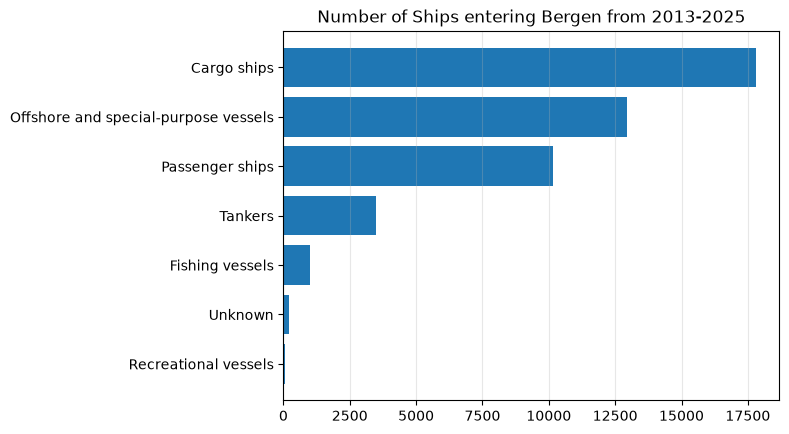

In [241]:
import matplotlib.pyplot as plt 
arrival_counts = (
    df_arrivals.groupby('vessel_category')
    .size()
    .sort_values(ascending=True)
)


plt.barh(arrival_counts.index, arrival_counts.values)
plt.grid(axis='x', alpha=0.3)

plt.title('Number of Ships entering Bergen from 2013-2025')


3.  Compute the mean `gross_tonnage` for each `vessel_category`. Display all
    categories in descending order of mean gross tonnage and create a horizontal
    bar chart of these means.

Text(0.5, 1.0, 'Average Gross Tonnage of each Vessel Category enetering Bergen from 2013-2025')

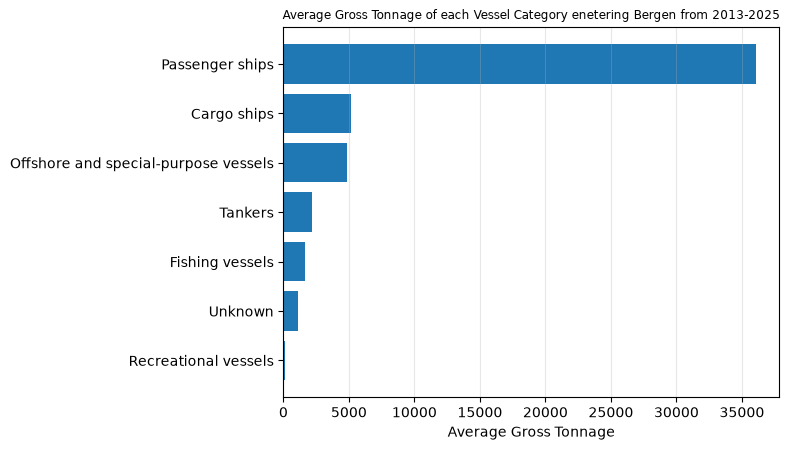

In [195]:
vessel_tonnage = (df_arrivals.groupby('vessel_category')['gross_tonnage'].mean().sort_values(ascending= True).round(0).astype(int))

plt.barh(vessel_tonnage.index, vessel_tonnage.values)
plt.grid(axis='x', alpha=0.3)
plt.xlabel('Average Gross Tonnage')
plt.title('Average Gross Tonnage of each Vessel Category enetering Bergen from 2013-2025', fontsize= 8.5)

4.  Count arrivals in each month separately for `Passenger ships` and
    `Cargo ships`. Store the results in a DataFrame named `df_monthly`, with one
    column per category, and plot both monthly series in one line chart.

    *Hint:* There are several ways to implement this. One way is to compute the monthly counts for each category separately and then combine the results into a single DataFrame.

In [210]:
df_arrivals

,vessel_type,vessel_category,gross_tonnage
arrival,,,
2013-01-01 03:00:00,Platform Supply Ship,Offshore and special-purpose vessels,3350.0
2013-01-01 12:10:00,Diving Support Vessel,Offshore and special-purpose vessels,7502.0
2013-01-01 19:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 01:00:00,Offshore Support Vessel,Offshore and special-purpose vessels,8552.0
2013-01-02 03:45:00,Tug,Offshore and special-purpose vessels,370.0
...,...,...,...
2025-12-31 15:45:00,Passenger/Ro-Ro Ship (Vehicles),Passenger ships,15519.0
2025-12-31 16:00:00,Offshore Tug/Supply Ship,Offshore and special-purpose vessels,4183.0
2025-12-31 18:00:00,Tug,Offshore and special-purpose vessels,302.0


In [216]:
df_arrivals.index

DatetimeIndex(['2013-01-01 03:00:00', '2013-01-01 12:10:00',
               '2013-01-01 19:00:00', '2013-01-02 01:00:00',
               '2013-01-02 03:45:00', '2013-01-02 05:00:00',
               '2013-01-02 07:00:00', '2013-01-02 08:30:00',
               '2013-01-02 09:00:00', '2013-01-02 10:30:00',
               ...
               '2025-12-31 10:30:00', '2025-12-31 13:05:00',
               '2025-12-31 14:30:00', '2025-12-31 14:45:00',
               '2025-12-31 15:00:00', '2025-12-31 15:45:00',
               '2025-12-31 16:00:00', '2025-12-31 18:00:00',
               '2025-12-31 18:23:00', '2025-12-31 21:00:00'],
              dtype='datetime64[us]', name='arrival', length=45620, freq=None)

In [232]:

passenger = df_arrivals[
    df_arrivals['vessel_category'] == 'Passenger ships'
]
cargo = df_arrivals[
    df_arrivals['vessel_category'] == 'Cargo ships'
]

passenger_monthly = (
    passenger
    .resample('MS')
    .size()
)

cargo_monthly = (
    cargo
    .resample('MS')
    .size()
)

df_monthly = pd.DataFrame(
    {'Passanger_Arrivals': passenger_monthly,
    'Cargo_Arrivals': cargo_monthly}).fillna(0)

df_monthly



,Passanger_Arrivals,Cargo_Arrivals
arrival,,
2013-01-01,10,137
2013-02-01,16,132
2013-03-01,18,149
2013-04-01,20,156
2013-05-01,65,177
...,...,...
2025-08-01,136,83
2025-09-01,102,82
2025-10-01,90,73


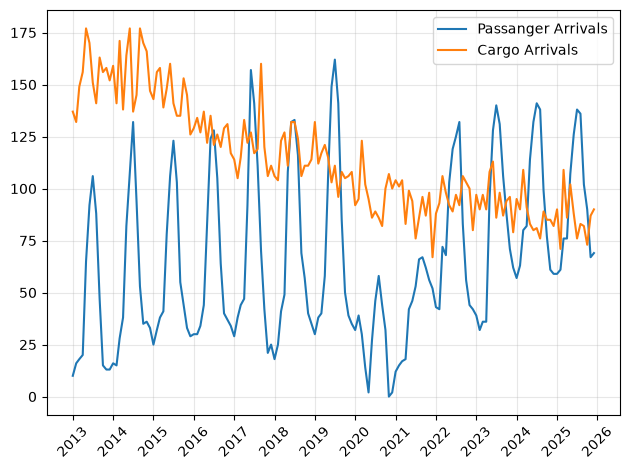

In [255]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.plot(df_monthly.index, df_monthly['Passanger_Arrivals'], label='Passanger Arrivals')
plt.plot(df_monthly.index, df_monthly['Cargo_Arrivals'], label='Cargo Arrivals')


ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)


plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)
plt.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()



5.  Use `groupby()` to calculate average monthly arrivals for each calendar
    month, from January through December. Create two seasonal bar charts, one
    per category, with a shared vertical scale. Describe the contrast in one
    sentence.

    *Hint:* Group `df_monthly` by `df_monthly.index.month`. Replace the resulting index with the supplied `month_names`. 
    
    *Hint:* Use
    `plot.bar(subplots=True, layout=(1, 2), sharey=True)` for the two panels when plotting with the pandas plotting API.

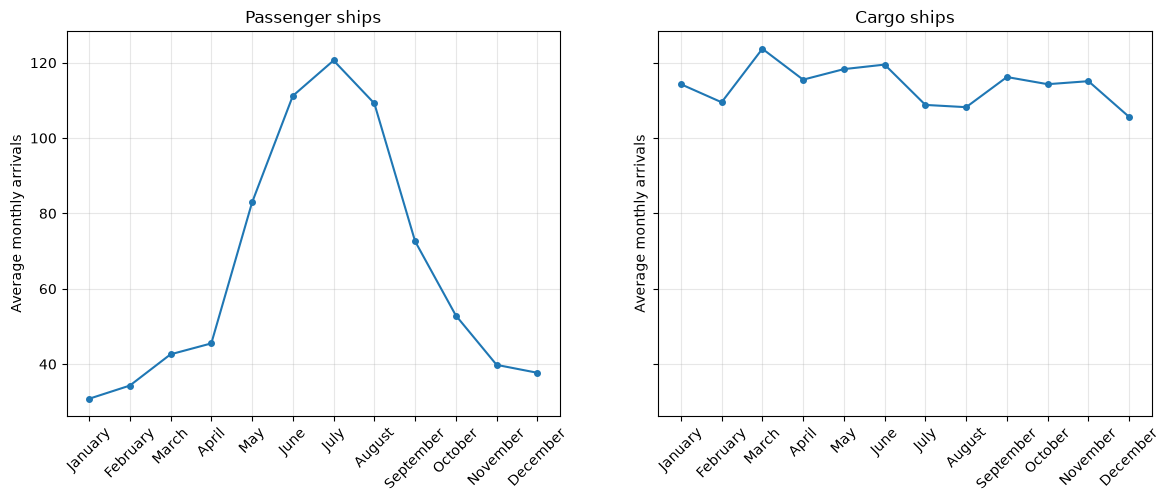

In [291]:
import matplotlib.pyplot as plt
month_names = [
    'January',
    'February',
    'March',
    'April',
    'May',
    'June',
    'July',
    'August',
    'September',
    'October',
    'November',
    'December',
]


df_seasonal = (df_monthly.groupby(df_monthly.index.month).mean().round(1))
df_seasonal.index = month_names

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
    sharey=True,
)

axes[0].plot(df_seasonal.index, df_seasonal['Passanger_Arrivals'], marker='o', markersize=4)
axes[0].set_title('Passenger ships')
axes[0].set_ylabel('Average monthly arrivals')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='x', alpha=0.3)
axes[0].grid(axis='y', alpha=0.3)

axes[1].plot(df_seasonal.index, df_seasonal['Cargo_Arrivals'], marker='o', markersize=4)
axes[1].set_title('Cargo ships')
axes[1].set_ylabel('Average monthly arrivals')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='x', alpha=0.3)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout
plt.show()
